# MWIS Experiment Comparison

This notebook compares the five saved four-minute MWIS scenarios and the three QPU-size sensitivity runs. Run it from the project root or the `results` folder. It validates matching Experiment 4 inputs and outputs before comparing them, then saves tables and figures under `results/experiment_comparison/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

# Find the results folder from either supported working directory.
HERE = Path.cwd()
RESULTS_DIR = HERE if (HERE / "_config.json").exists() else HERE / "results"
OUTPUT_DIR = RESULTS_DIR / "experiment_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SCENARIOS = [
    {"run": "exp1_baseline_s100_g50_4min", "label": "Baseline 100/50", "satellites": 100, "gateways": 50},
    {"run": "exp2_satellite_s200_g50_4min", "label": "Satellites 200/50", "satellites": 200, "gateways": 50},
    {"run": "exp2_satellite_s500_g50_4min", "label": "Satellites 500/50", "satellites": 500, "gateways": 50},
    {"run": "exp3_gateway_s500_g25_4min", "label": "Gateways 500/25", "satellites": 500, "gateways": 25},
    {"run": "exp3_gateway_s500_g100_4min", "label": "Gateways 500/100", "satellites": 500, "gateways": 100},
]

if not (RESULTS_DIR / "runs" / "mwis_pipeline").is_dir():
    raise FileNotFoundError("Run this notebook from the project root or results folder.")


In [2]:
def read_metrics(path):
    frame = pd.read_csv(path)
    return dict(zip(frame["metric"], frame["value"]))


def load_scenario(spec):
    mwis_dir = RESULTS_DIR / "runs" / "mwis_pipeline" / spec["run"]
    qubo_dir = RESULTS_DIR / "runs" / "qubo_annealing" / spec["run"]
    mwis_config = json.loads((mwis_dir / "run_config_log.json").read_text(encoding="utf-8"))
    qubo_config = json.loads((qubo_dir / "run_config_log.json").read_text(encoding="utf-8"))
    expected_input = f"data/experiment_inputs/exp1_3_snapshot_2026-09-27/scenario_inputs/slots_s{spec['satellites']}_g{spec['gateways']}.csv"

    if mwis_config["candidate_slot_csv"] != expected_input or qubo_config["candidate_slot_csv"] != expected_input:
        raise ValueError(f"Unexpected input file for {spec['run']}.")
    if qubo_config["qubo_input_run"] != f"runs/mwis_pipeline/{spec['run']}":
        raise ValueError(f"QUBO run does not match MWIS run for {spec['run']}.")

    mwis = read_metrics(mwis_dir / "final_summary.csv")
    reconstructed = read_metrics(qubo_dir / "reconstructed_summary.csv")
    terminals = pd.read_csv(qubo_dir / "terminal_qubo_summary.csv")
    decomposition = pd.read_csv(mwis_dir / "decomposition_summary.csv")
    root_type = dict(zip(decomposition["component_id"], decomposition["root_type"]))
    terminals["provenance"] = terminals["original_component_id"].map(root_type)

    direct_terminals = int((terminals["provenance"] == "terminal").sum())
    separator_terminals = int((terminals["provenance"] == "separator").sum())
    if direct_terminals != int(float(mwis["Subgraphs solved directly"])):
        raise ValueError(f"Direct-terminal count differs for {spec['run']}.")
    if separator_terminals != int(float(mwis["Subgraphs solved exactly with separator decomposition"])):
        raise ValueError(f"Separator-terminal count differs for {spec['run']}.")

    return {
        **spec,
        "mwis_dir": mwis_dir,
        "qubo_dir": qubo_dir,
        "mwis": mwis,
        "reconstructed": reconstructed,
        "terminals": terminals,
        "nodes": pd.read_csv(mwis_dir / "conflict_graph_nodes.csv"),
        "edges": pd.read_csv(mwis_dir / "conflict_graph_edges.csv"),
        "direct_terminals": direct_terminals,
        "separator_terminals": separator_terminals,
        "qpu_node_limit": int(mwis_config["max_qpu_terminal_nodes"]),
        "qpu_coupler_limit": int(mwis_config["max_qpu_terminal_couplers"]),
    }


RUN_DATA = [load_scenario(spec) for spec in SCENARIOS]


In [3]:
records = []
for data in RUN_DATA:
    mwis = data["mwis"]
    reconstructed = data["reconstructed"]
    terminals = data["terminals"]
    records.append({
        "Scenario": data["label"],
        "Satellites": data["satellites"],
        "Gateways": data["gateways"],
        "Candidate slots": len(data["nodes"]),
        "Conflict edges": len(data["edges"]),
        "Natural components": int(float(mwis["Number of components (total)"])),
        "Direct QUBOs": data["direct_terminals"],
        "Separator QUBOs": data["separator_terminals"],
        "Incomplete components": int(float(mwis["Components with incomplete separator decomposition"])),
        "Incomplete nodes": int(float(mwis["Incomplete decomposition nodes (all states)"])),
        "Terminal QUBOs": len(terminals),
        "Annealed used": int(float(reconstructed["Annealed terminal subgraphs used"])),
        "Selected contacts": int(float(reconstructed["Selected contacts"])),
        "Feasible objective": float(reconstructed["Total feasible objective"]),
        "Upper bound": float(reconstructed["MWIS producer conservative objective upper bound"]),
        "Gap (%)": float(reconstructed["Annealed schedule relative gap bound (%)"]),
        "Max QUBO nodes": int(terminals["variables"].max()) if not terminals.empty else 0,
        "Max QUBO couplers": int(terminals["couplers"].max()) if not terminals.empty else 0,
    })

comparison = pd.DataFrame(records)
comparison.to_csv(OUTPUT_DIR / "mwis_experiment_summary.csv", index=False, float_format="%.6f")

display(comparison.style.format({
    "Feasible objective": "{:,.3f}",
    "Upper bound": "{:,.3f}",
    "Gap (%)": "{:.3f}",
}).hide(axis="index"))


Scenario,Satellites,Gateways,Candidate slots,Conflict edges,Natural components,Direct QUBOs,Separator QUBOs,Incomplete components,Incomplete nodes,Terminal QUBOs,Annealed used,Selected contacts,Feasible objective,Upper bound,Gap (%),Max QUBO nodes,Max QUBO couplers
Baseline 100/50,100,50,422,90,333,82,0,0,0,82,82,339,"22,807.666","22,807.666",0.000,3,3
Satellites 200/50,200,50,764,350,471,180,0,0,0,180,180,524,"36,801.511","36,801.511",0.000,9,13
Satellites 500/50,500,50,3220,6515,561,349,209,0,0,558,401,1239,"87,115.245","87,115.245",0.000,30,119
Gateways 500/25,500,25,1685,3434,265,170,122,0,0,292,200,633,"44,965.184","44,965.184",0.000,30,119
Gateways 500/100,500,100,6706,14226,1083,662,470,1,1,1132,782,2499,"177,096.722","179,089.212",1.113,30,126


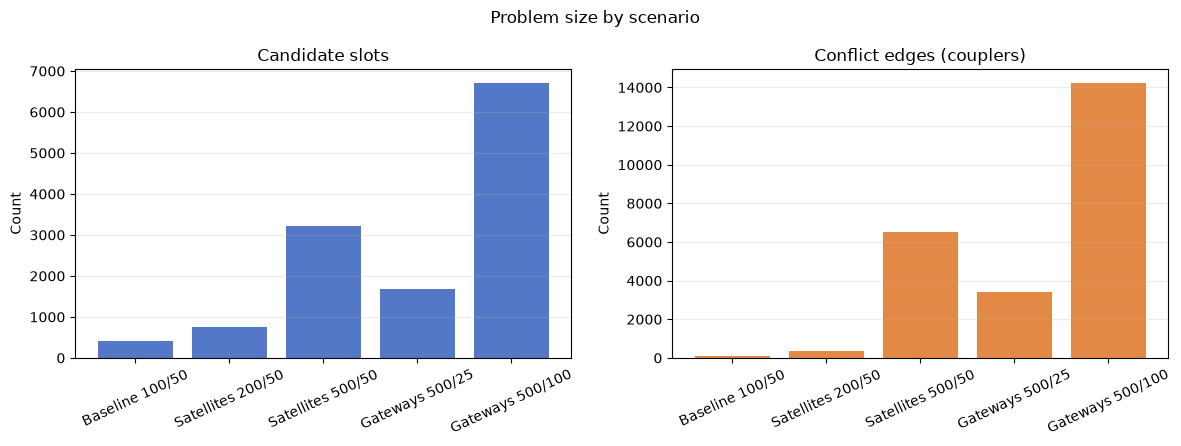

In [4]:
# Figure 1: growth in candidate slots and conflict edges.
labels = comparison["Scenario"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(labels, comparison["Candidate slots"], color="#5478c8")
axes[0].set_title("Candidate slots")
axes[0].set_ylabel("Count")
axes[1].bar(labels, comparison["Conflict edges"], color="#e28a45")
axes[1].set_title("Conflict edges (couplers)")
axes[1].set_ylabel("Count")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Problem size by scenario")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_1_problem_size.png", dpi=180, bbox_inches="tight")
plt.show()


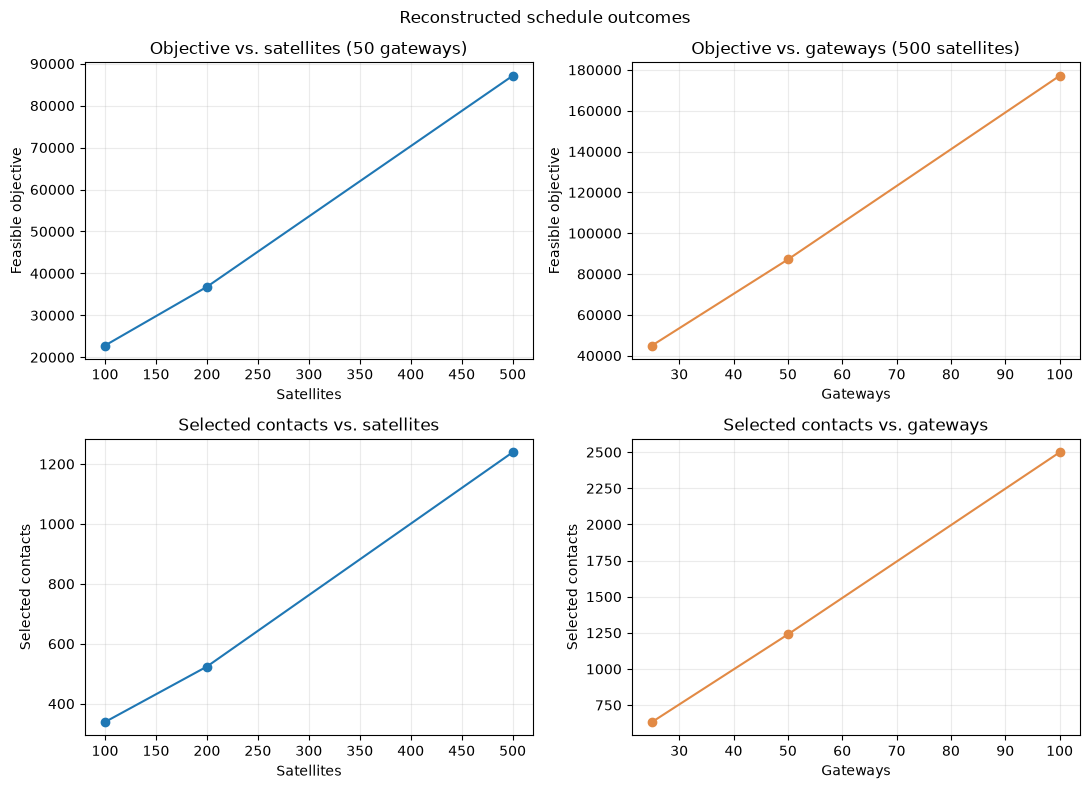

In [5]:
# Figure 2: schedule outcomes as satellite and gateway counts change.
satellite_runs = comparison[comparison["Gateways"] == 50].sort_values("Satellites")
gateway_runs = comparison[comparison["Satellites"] == 500].sort_values("Gateways")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(satellite_runs["Satellites"], satellite_runs["Feasible objective"], marker="o")
axes[0, 0].set(title="Objective vs. satellites (50 gateways)", xlabel="Satellites", ylabel="Feasible objective")
axes[0, 1].plot(gateway_runs["Gateways"], gateway_runs["Feasible objective"], marker="o", color="#e28a45")
axes[0, 1].set(title="Objective vs. gateways (500 satellites)", xlabel="Gateways", ylabel="Feasible objective")
axes[1, 0].plot(satellite_runs["Satellites"], satellite_runs["Selected contacts"], marker="o")
axes[1, 0].set(title="Selected contacts vs. satellites", xlabel="Satellites", ylabel="Selected contacts")
axes[1, 1].plot(gateway_runs["Gateways"], gateway_runs["Selected contacts"], marker="o", color="#e28a45")
axes[1, 1].set(title="Selected contacts vs. gateways", xlabel="Gateways", ylabel="Selected contacts")
for ax in axes.flat:
    ax.grid(alpha=0.25)
fig.suptitle("Reconstructed schedule outcomes")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_2_schedule_outcomes.png", dpi=180, bbox_inches="tight")
plt.show()


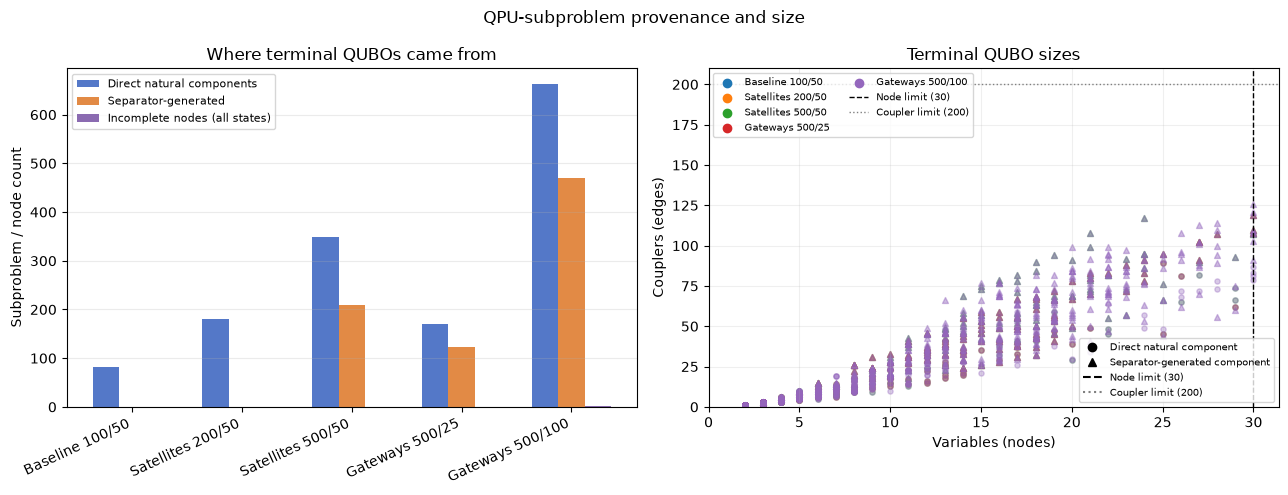

Saved table and figures to: C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\experiment_comparison


In [6]:
# Figure 3: terminal provenance and terminal sizes against configured limits.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = range(len(comparison))
width = 0.24
axes[0].bar([i - width for i in x], comparison["Direct QUBOs"], width, label="Direct natural components", color="#5478c8")
axes[0].bar(x, comparison["Separator QUBOs"], width, label="Separator-generated", color="#e28a45")
axes[0].bar([i + width for i in x], comparison["Incomplete nodes"], width, label="Incomplete nodes (all states)", color="#8b6bb1")
axes[0].set_xticks(list(x), comparison["Scenario"], rotation=25, ha="right")
axes[0].set_ylabel("Subproblem / node count")
axes[0].set_title("Where terminal QUBOs came from")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.25)

colors = plt.get_cmap("tab10").colors
for index, data in enumerate(RUN_DATA):
    terminals = data["terminals"]
    direct = terminals[terminals["provenance"] == "terminal"]
    separator = terminals[terminals["provenance"] == "separator"]
    axes[1].scatter(direct["variables"], direct["couplers"], s=14, alpha=0.35, color=colors[index], marker="o")
    axes[1].scatter(separator["variables"], separator["couplers"], s=18, alpha=0.45, color=colors[index], marker="^")
    axes[1].scatter([], [], color=colors[index], marker="o", label=data["label"])

node_limit = RUN_DATA[0]["qpu_node_limit"]
coupler_limit = RUN_DATA[0]["qpu_coupler_limit"]
axes[1].axvline(node_limit, color="black", linestyle="--", linewidth=1, label=f"Node limit ({node_limit})")
axes[1].axhline(coupler_limit, color="gray", linestyle=":", linewidth=1, label=f"Coupler limit ({coupler_limit})")
axes[1].set(xlabel="Variables (nodes)", ylabel="Couplers (edges)", title="Terminal QUBO sizes")
axes[1].set_xlim(left=0)
axes[1].set_ylim(bottom=0)
axes[1].grid(alpha=0.2)
scenario_legend = axes[1].legend(fontsize=7, loc="upper left", ncol=2)
axes[1].add_artist(scenario_legend)
axes[1].legend(handles=[
    Line2D([], [], color="black", marker="o", linestyle="", label="Direct natural component"),
    Line2D([], [], color="black", marker="^", linestyle="", label="Separator-generated component"),
    Line2D([], [], color="black", linestyle="--", label=f"Node limit ({node_limit})"),
    Line2D([], [], color="gray", linestyle=":", label=f"Coupler limit ({coupler_limit})"),
], fontsize=7, loc="lower right")
fig.suptitle("QPU-subproblem provenance and size")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_3_qubo_provenance_and_size.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved table and figures to: {OUTPUT_DIR}")


## Experiment 4: QPU-size sensitivity

This section validates the three 500-satellite/50-gateway runs before comparing them. It checks that inputs and graphs match, each terminal QUBO fits its configured limits, and the annealed schedules are feasible and correctly reconstructed.

In [ ]:
EXP4_RUNS = [
    {'run': 'exp4_qpu_s500_g50_n20_c100', 'profile': '20 / 100', 'nodes': 20, 'couplers': 100},
    {'run': 'exp4_qpu_s500_g50_n30_c200', 'profile': '30 / 200', 'nodes': 30, 'couplers': 200},
    {'run': 'exp4_qpu_s500_g50_n50_c350', 'profile': '50 / 350', 'nodes': 50, 'couplers': 350},
]
EXPECTED_INPUT = 'data/experiment_inputs/exp1_3_snapshot_2026-09-27/scenario_inputs/slots_s500_g50.csv'
exp4_rows = []
reference_graph = None

for spec in EXP4_RUNS:
    mwis_dir = RESULTS_DIR / 'runs' / 'mwis_pipeline' / spec['run']
    qubo_dir = RESULTS_DIR / 'runs' / 'qubo_annealing' / spec['run']
    mwis_config = json.loads((mwis_dir / 'run_config_log.json').read_text(encoding='utf-8'))
    qubo_config = json.loads((qubo_dir / 'run_config_log.json').read_text(encoding='utf-8'))
    if mwis_config['candidate_slot_csv'] != EXPECTED_INPUT or qubo_config['candidate_slot_csv'] != EXPECTED_INPUT:
        raise ValueError('Input mismatch for {}'.format(spec['run']))
    if (mwis_config['max_qpu_terminal_nodes'], mwis_config['max_qpu_terminal_couplers']) != (spec['nodes'], spec['couplers']):
        raise ValueError('QPU limits mismatch for {}'.format(spec['run']))
    if mwis_config['exact_clique_node_limit'] != 50 or qubo_config['qubo_input_run'] != 'runs/mwis_pipeline/' + spec['run']:
        raise ValueError('Exact limit or stage pairing mismatch for {}'.format(spec['run']))
    if any(qubo_config[key] != mwis_config[key] for key in ['qubo_reward_factor', 'qubo_penalty_factor', 'num_reads', 'base_seed']):
        raise ValueError('Annealing settings mismatch for {}'.format(spec['run']))

    nodes = pd.read_csv(mwis_dir / 'conflict_graph_nodes.csv')
    edges = pd.read_csv(mwis_dir / 'conflict_graph_edges.csv')
    graph_signature = (tuple(sorted(nodes['slot_id'].astype(str))), tuple(sorted(tuple(sorted(row)) for row in edges.iloc[:, :2].astype(str).itertuples(index=False, name=None))))
    if reference_graph is None:
        reference_graph = graph_signature
    elif graph_signature != reference_graph:
        raise ValueError('The three cases do not use the same conflict graph.')

    terminals = pd.read_csv(qubo_dir / 'terminal_qubo_summary.csv')
    annealing = pd.read_csv(qubo_dir / 'annealing_results.csv')
    if len(terminals) != len(annealing) or set(terminals['terminal_id']) != set(annealing['terminal_id']):
        raise ValueError('Some terminal QUBOs were not annealed for {}'.format(spec['run']))
    if not annealing['is_independent'].astype(bool).all() or set(annealing['num_reads']) != {qubo_config['num_reads']} or not ((annealing['energy'] - annealing['recomputed_energy']).abs() < 1e-8).all():
        raise ValueError('Invalid annealing records for {}'.format(spec['run']))
    if (terminals['variables'] > spec['nodes']).any() or (terminals['couplers'] > spec['couplers']).any():
        raise ValueError('A terminal QUBO exceeds its configured limits for {}'.format(spec['run']))

    mwis = read_metrics(mwis_dir / 'final_summary.csv')
    reconstructed = read_metrics(qubo_dir / 'reconstructed_summary.csv')
    schedule = pd.read_csv(qubo_dir / 'reconstructed_schedule.csv')
    selected = set(schedule['slot_id'].astype(str))
    conflicts = sum(u in selected and v in selected for u, v in edges.iloc[:, :2].astype(str).itertuples(index=False, name=None))
    objective = float(schedule['weight'].sum())
    reported = float(reconstructed['Total feasible objective'])
    upper = float(reconstructed['MWIS producer conservative objective upper bound'])
    if conflicts or abs(objective - reported) > 1e-6 or reported > upper + 1e-6:
        raise ValueError('Reconstructed schedule failed validation for {}'.format(spec['run']))

    decomposition = pd.read_csv(mwis_dir / 'decomposition_summary.csv')
    root_type = dict(zip(decomposition['component_id'], decomposition['root_type']))
    terminals['provenance'] = terminals['original_component_id'].map(root_type)
    direct = int((terminals['provenance'] == 'terminal').sum())
    separator = int((terminals['provenance'] == 'separator').sum())
    if direct + separator != len(terminals):
        raise ValueError('Unknown terminal provenance for {}'.format(spec['run']))
    exp4_rows.append({
        'QPU profile (nodes / couplers)': spec['profile'], 'Node limit': spec['nodes'], 'Coupler limit': spec['couplers'],
        'Candidate slots': len(nodes), 'Conflict edges': len(edges),
        'Natural components': int(float(mwis['Number of components (total)'])),
        'Direct QUBOs': direct,
        'Separator QUBOs': separator,
        'Terminal QUBOs': len(terminals), 'Terminal QUBOs used': int(float(reconstructed['Annealed terminal subgraphs used'])),
        'Max terminal nodes': int(terminals['variables'].max()), 'Max terminal couplers': int(terminals['couplers'].max()),
        'Incomplete separator nodes': int(float(mwis['Incomplete decomposition nodes (all states)'])),
        'Selected contacts': len(schedule), 'Annealed objective': reported, 'MWIS upper bound': upper,
        'Gap (%)': float(reconstructed['Annealed schedule relative gap bound (%)']), 'Validation': 'PASS',
    })

exp4_comparison = pd.DataFrame(exp4_rows)
exp4_comparison.to_csv(OUTPUT_DIR / 'mwis_exp4_qpu_size_summary.csv', index=False, float_format='%.6f')
display(exp4_comparison.style.format({'Annealed objective': '{:,.3f}', 'MWIS upper bound': '{:,.3f}', 'Gap (%)': '{:.3f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = exp4_comparison['QPU profile (nodes / couplers)']
x = range(len(exp4_comparison))
axes[0].bar(x, exp4_comparison['Direct QUBOs'], label='Natural direct', color='#5478c8')
axes[0].bar(x, exp4_comparison['Separator QUBOs'], bottom=exp4_comparison['Direct QUBOs'], label='Separator-generated', color='#e28a45')
axes[0].set_xticks(list(x), labels)
axes[0].set(title='Terminal QUBOs by source', xlabel='QPU limit: nodes / couplers', ylabel='Subproblem count')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.25)
axes[1].bar(labels, exp4_comparison['Gap (%)'], color='#8b6bb1')
axes[1].set(title='Conservative optimality gap', xlabel='QPU limit: nodes / couplers', ylabel='Gap (%)')
axes[1].grid(axis='y', alpha=0.25)
for i, row in exp4_comparison.iterrows():
    axes[1].text(i, row['Gap (%)'] + 0.04, '{:.2f}%'.format(row['Gap (%)']), ha='center', va='bottom')
fig.suptitle('Experiment 4: QPU-size sensitivity')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'figure_4_qpu_size_sensitivity.png', dpi=180, bbox_inches='tight')
plt.show()
print('Experiment 4 checks passed; comparison saved to {}'.format(OUTPUT_DIR))